# Ericsson lead scoring: which leads should sales call first?

**Business question:** if a sales team can only call 30% of new leads, which ones should they call, and what share of eventual conversions does that capture?
**Decision-maker:** sales / marketing operations manager.

**Data:** Ericsson Marketo export from a UT Dallas Marketing Analytics class (MKT 4337). One row per *marketing activity* (email sent, opened, clicked, page visit, form fill), not per lead. Raw data is not included in this repo.

**Plan**
1. Inspect the data and confirm what each column means.
2. Reproduce the baseline: one row per lead, model on job role only.
3. Add early-engagement features from each lead's first 30 days only, and drop any that look like leakage.
4. Find out who actually converts (existing customers vs. new prospects), then validate with 5-fold cross-validation at lead level.
5. Translate scores into a business number: how many conversions does calling the top X% capture?

To run in Colab: upload `MarketoData-Final.xlsx` (folder icon on the left), then Runtime → Run all.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sqlite3, os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
SEED = 42
os.makedirs('charts', exist_ok=True); os.makedirs('tableau', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

raw = pd.read_excel('MarketoData-Final.xlsx', sheet_name=0)
raw['activityDate'] = pd.to_datetime(raw['activityDate'], errors='coerce')
print(raw.shape)
print(raw.dtypes)

(299999, 14)
type                                str
leadId                            int64
company                             str
industry                            str
cu_customer_unit__c                 str
department__c                       str
level__c                            str
title                            object
status                              str
primaryAttributeValue               str
programName                         str
cccontacttype                       str
activityDate             datetime64[us]
leadstatus                          str
dtype: object


## 1. What is in the data?
Key checks: `status` is the **activity type**; `leadstatus` is the lead's **current** status repeated on every row. There is no date for when a lead converted, so we cannot simply filter to "activities before conversion". Section 3 handles that with a fixed 30-day window and a time split.

In [2]:
print('activity rows:', len(raw), '| unique leads:', raw.leadId.nunique())
print('date range:', raw.activityDate.min().date(), 'to', raw.activityDate.max().date(), '| missing dates:', raw.activityDate.isna().sum())
display(raw['status'].value_counts().rename('activity rows').to_frame())
display(raw['leadstatus'].value_counts().rename('activity rows').to_frame())
print('leads with more than one leadstatus value:', (raw.groupby('leadId').leadstatus.nunique() > 1).sum())
print('activities per lead (median):', raw.groupby('leadId').size().median())

activity rows: 299999 | unique leads: 34296
date range: 2024-01-01 to 2025-09-12 | missing dates: 0
leads with more than one leadstatus value: 251
activities per lead (median): 8.0


,activity rows
status,
Send Email,126170
Email Delivered,125035
Add to Nurture,18192
Open Email,18002
Click Email,8290
Visit Webpage,2905
Email Bounced Soft,676
Fill Out Form,414
Email Bounced,210


,activity rows
leadstatus,
Prospect,192751
Converted,33577
Visitor,8934
Marketing Accepted,6284
Disqualified,3754
Rejected,1417
Sales Accepted,238
Sales Qualified,89
Lost,40


## 2. Baseline: one row per lead, job-role features only
A lead counts as converted if **any** of its rows has `leadstatus == 'Converted'`. Industry, department and level are the lead's first non-missing value.

The original class model used activity rows with a random split, which put the same lead in both training and test data (leakage). Rebuilding at lead level fixes that.

In [3]:
raw['converted_row'] = (raw.leadstatus == 'Converted').astype(int)
leads = (raw.groupby('leadId')
           .agg(converted=('converted_row', 'max'),
                industry=('industry', 'first'), department=('department__c', 'first'),
                level=('level__c', 'first'), contact_type=('cccontacttype', 'first'),
                first_seen=('activityDate', 'min'))
           .reset_index())
for c in ['industry', 'department', 'level', 'contact_type']:
    leads[c] = leads[c].fillna('Missing')
print(f"leads: {len(leads):,} | converted: {leads.converted.sum():,} ({leads.converted.mean():.1%})")

def seg(df, col, min_leads=50):
    t = df.groupby(col).converted.agg(leads='count', conversions='sum', rate='mean')
    t = t[t.leads >= min_leads].copy()
    t['rate_%'] = (100 * t.pop('rate')).round(1)
    return t.sort_values('rate_%', ascending=False)

by_level, by_dept = seg(leads, 'level'), seg(leads, 'department')
display(by_level); display(by_dept)

leads: 34,296 | converted: 3,703 (10.8%)


,leads,conversions,rate_%
level,,,
Staff,15579,1863,12.0
Consultant,1134,132,11.6
Manager,7918,902,11.4
Director,2301,228,9.9
Missing,4710,426,9.0
VP,1118,89,8.0
Dept. Heads,111,7,6.3
CXO,471,25,5.3
Administrator,357,17,4.8


,leads,conversions,rate_%
department,,,
Purchasing / Supply Chain / Sourcing,264,46,17.4
Project Management,751,105,14.0
Analyst,474,66,13.9
Other,348,48,13.8
Information Technology,6591,891,13.5
Business Operations,312,41,13.1
Engineering,3877,504,13.0
Network Operations,2516,316,12.6
Strategy,921,114,12.4


In [4]:
ROLE = ['industry', 'department', 'level']
X = pd.get_dummies(leads[ROLE]); y = leads.converted
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
p = rf.predict_proba(Xte)[:, 1]

def top_decile(y_true, score):
    y_true = np.asarray(y_true); top = y_true[np.argsort(-score)][: len(score) // 10]
    return top.mean(), top.mean() / y_true.mean()

rate10, lift10 = top_decile(yte, p)
print(f"BASELINE (random split, role only)  AUC {roc_auc_score(yte, p):.3f} | top 10% convert at {rate10:.1%} ({lift10:.1f}x)")
print(f"accuracy of predicting 'nobody converts': {1 - yte.mean():.1%}  <- why accuracy is the wrong metric here")

BASELINE (random split, role only)  AUC 0.690 | top 10% convert at 22.6% (2.1x)
accuracy of predicting 'nobody converts': 89.2%  <- why accuracy is the wrong metric here


## 3. Early-engagement features (first 30 days only)
For each lead, keep only activities in the 30 days after its first activity and count opens, clicks, page visits, form fills, bounces and nurture adds, plus distinct programs, active days and click rate.

**Leakage control:** a fixed 30-day window from first contact limits the model to early behavior, before most follow-up that might only happen *because* a lead converted. Leads first seen after 2025-08-13 are dropped because their 30-day window is incomplete.

In [5]:
WINDOW = pd.Timedelta(days=30)
CUTOFF = raw.activityDate.max() - WINDOW
act = raw.merge(leads[['leadId', 'first_seen']], on='leadId')
early = act[act.activityDate < act.first_seen + WINDOW]

counts = (early.pivot_table(index='leadId', columns='status', values='activityDate', aggfunc='count', fill_value=0))
STATUS = {'Open Email': 'opens', 'Click Email': 'clicks', 'Visit Webpage': 'page_visits',
          'Fill Out Form': 'form_fills', 'Email Bounced Soft': 'bounces', 'Add to Nurture': 'nurture_adds',
          'Email Delivered': 'delivered'}
feat = counts.reindex(columns=list(STATUS), fill_value=0).rename(columns=STATUS)
feat['programs'] = early.groupby('leadId').programName.nunique()
feat['active_days'] = early.groupby('leadId').activityDate.apply(lambda s: s.dt.normalize().nunique())
feat['click_rate'] = np.where(feat.delivered > 0, feat.clicks / feat.delivered.clip(lower=1), 0)
ENG = ['opens', 'clicks', 'page_visits', 'form_fills', 'bounces', 'nurture_adds', 'programs', 'active_days', 'click_rate']

data = leads.merge(feat[ENG].reset_index(), on='leadId', how='left').fillna({c: 0 for c in ENG})
data = data[data.first_seen <= CUTOFF].copy()
print(f"window cutoff: leads first seen on or before {CUTOFF.date()} | leads kept: {len(data):,}")
display(data.groupby('converted')[ENG].mean().T.round(2).rename(columns={0: 'not converted (avg)', 1: 'converted (avg)'}))

window cutoff: leads first seen on or before 2025-08-13 | leads kept: 34,294


converted,not converted (avg),converted (avg)
opens,0.28,0.13
clicks,0.12,0.06
page_visits,0.04,0.02
form_fills,0.01,0.01
bounces,0.00,0.00
nurture_adds,0.49,0.83
programs,1.25,1.09
active_days,2.58,2.72
click_rate,0.05,0.02


## 4. Who actually converts? Existing customers vs. new prospects
`cccontacttype` splits leads into existing **Customers** and new **prospects** (Prospective Customer, Prospect, Partner…). Conversion is almost entirely an existing-customer event.

Caveat: the data has no date for when contact type was set, so we can't rule out that some contacts were relabeled "Customer" *after* converting. Contact type is therefore used to **choose the population**, never as a model feature.

In [6]:
display(seg(data, 'contact_type', min_leads=1))
data['is_customer'] = (data.contact_type == 'Customer')
cust_share = data.loc[data.is_customer, 'converted'].sum() / data.converted.sum()
print(f"existing customers: {data.is_customer.sum():,} leads, {data[data.is_customer].converted.mean():.1%} convert")
print(f"new prospects & others: {(~data.is_customer).sum():,} leads, {data[~data.is_customer].converted.mean():.1%} convert")
print(f"share of all conversions that come from existing customers: {cust_share:.1%}")

existing customers: 9,543 leads, 37.5% convert
new prospects & others: 24,751 leads, 0.5% convert
share of all conversions that come from existing customers: 96.7%


,leads,conversions,rate_%
contact_type,,,
Customer,9543,3581,37.5
Consultant,91,1,1.1
Prospective Customer,21265,111,0.5
Prospect,2061,9,0.4
Ericsson Employee,343,1,0.3
Agency,5,0,0.0
Educational Institution or Student,36,0,0.0
Ericsson employee,2,0,0.0
Industry Analyst,2,0,0.0


**Reframed business question:** account teams can't call every customer contact. *Which existing-customer contacts should they call first?*

The job-level pattern is even sharper inside customers:

In [7]:
cust = data[data.is_customer].copy()
cust_level, cust_dept = seg(cust, 'level'), seg(cust, 'department')
display(cust_level); display(cust_dept)

,leads,conversions,rate_%
level,,,
Manager,1899,887,46.7
Staff,4454,1792,40.2
Director,652,215,33.0
Missing,1267,417,32.9
Consultant,424,127,30.0
VP,480,86,17.9
Other,56,10,17.9
Administrator,91,16,17.6
CXO,188,23,12.2


,leads,conversions,rate_%
department,,,
Other,88,46,52.3
Business Development,188,98,52.1
Analyst,132,62,47.0
Project Management,219,100,45.7
Business Operations,90,41,45.6
Network Operations,672,294,43.8
Engineering,1116,479,42.9
Information Technology,2170,865,39.9
Strategy,282,110,39.0


## 5. Validation design
A time split (train on older leads, test on newer) is the ideal check, but this extract can't support it: most leads first appear in early 2024, and newer leads haven't had time to convert, so their conversion rate is artificially low.

In [8]:
display(data.groupby(data.first_seen.dt.to_period('Q')).converted.agg(leads='count', conversion_rate='mean').round(3))

,leads,conversion_rate
first_seen,,
2024Q1,29083,0.117
2024Q2,2575,0.089
2024Q3,573,0.049
2024Q4,61,0.082
2025Q1,373,0.008
2025Q2,1528,0.026
2025Q3,101,0.040


So we use **5-fold stratified cross-validation at lead level**. Each lead is one row, so the same lead never appears in both training and test folds (the leak in the original class model).

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def design(df, cols_cat, cols_num):
    Xd = pd.get_dummies(df[cols_cat]) if cols_cat else pd.DataFrame(index=df.index)
    return pd.concat([Xd, df[cols_num]], axis=1).astype(float)

def models():
    return {'Logistic Regression': LogisticRegression(max_iter=3000),
            'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
            'Gradient Boosting': GradientBoostingClassifier(random_state=SEED)}

# Two kinds of activity are mixed in this data:
#  - things the CONTACT did: opened, clicked, visited a page, filled a form, plus click rate
#  - things MARKETING did to the contact: sends, nurture adds, which programs, which days they were emailed
# Marketing's actions can depend on the lead's status (e.g. 'Add to Nurture' comes from ONE automated program,
# and 78% of converted customers were added on day 1 vs 28% of others). With no conversion date we can't prove
# those actions came before conversion, so the headline model uses contact behavior only.
nurt = act[act.status == 'Add to Nurture']
print('programs behind Add to Nurture:', nurt.programName.value_counts().head(2).to_dict())
BEHAVIOR = ['opens', 'clicks', 'page_visits', 'form_fills', 'click_rate']
MARKETER = ['nurture_adds', 'programs', 'active_days', 'bounces']

rows, scores = [], {}
for fs_name, num in [('Role only', []), ('Role + contact behavior', BEHAVIOR), ('+ marketer-driven activity (likely leak)', BEHAVIOR + MARKETER)]:
    Xd = design(cust, ROLE, num)
    for m_name, m in models().items():
        s = cross_val_predict(m, Xd, cust.converted, cv=cv, method='predict_proba')[:, 1]
        r10, l10 = top_decile(cust.converted, s)
        rows.append({'features': fs_name, 'model': m_name, 'AUC': round(roc_auc_score(cust.converted, s), 3),
                     'top 10% conv %': round(100 * r10, 1), 'lift': round(l10, 2)})
        scores[(fs_name, m_name)] = s
results = pd.DataFrame(rows)
print(f"population: {len(cust):,} existing-customer contacts, base rate {cust.converted.mean():.1%}")
display(results)

programs behind Add to Nurture: {'Pro_LaserPhoenix_JH3': 18191, 'Pro_CrystalNexus_YMY': 1}
population: 9,543 existing-customer contacts, base rate 37.5%


,features,model,AUC,top 10% conv %,lift
0,Role only,Logistic Regression,0.630,51.2,1.36
1,Role only,Random Forest,0.674,62.3,1.66
2,Role only,Gradient Boosting,0.668,61.3,1.63
3,Role + contact behavior,Logistic Regression,0.640,53.8,1.43
4,Role + contact behavior,Random Forest,0.691,64.6,1.72
5,Role + contact behavior,Gradient Boosting,0.685,62.4,1.66
6,+ marketer-driven activity (likely leak),Logistic Regression,0.816,75.5,2.01
7,+ marketer-driven activity (likely leak),Random Forest,0.865,86.3,2.30
8,+ marketer-driven activity (likely leak),Gradient Boosting,0.858,86.2,2.30


## 6. Business result: how many conversions does calling the top X% capture?

best: ('Role + contact behavior', 'Random Forest')


,call top,conversions captured,conversion rate of called group
0,10%,17%,65%
1,20%,31%,58%
2,30%,43%,54%
3,50%,67%,50%


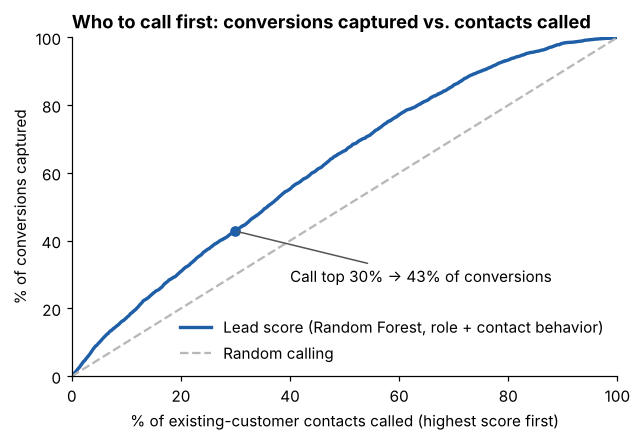

In [10]:
best_key = max([k for k in scores if not k[0].startswith('+')], key=lambda k: results.set_index(['features', 'model']).loc[k, 'AUC'])
s_best = scores[best_key]
s_base = scores[('Role only', best_key[1])]
yb = cust.converted
print('best:', best_key)

def capture(y_true, score):
    y_sorted = np.asarray(y_true)[np.argsort(-score)]
    pct = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
    return pct, np.cumsum(y_sorted) / y_sorted.sum()

def cap_at(y_true, score, q):
    pct, cap = capture(y_true, score); return cap[int(q * len(cap)) - 1]

cap_table = pd.DataFrame([{'call top': f'{int(q*100)}%',
                           'conversions captured': f'{cap_at(yb, s_best, q):.0%}',
                           'conversion rate of called group': f'{np.asarray(yb)[np.argsort(-s_best)][:int(q*len(yb))].mean():.0%}'}
                          for q in [0.1, 0.2, 0.3, 0.5]])
display(cap_table)

fig, ax = plt.subplots(figsize=(6.4, 4))
pct, cap = capture(yb, s_best)
ax.plot(pct * 100, cap * 100, label=f'Lead score ({best_key[1]}, {best_key[0].lower()})', color='#1f5fa8', lw=2.2)
ax.plot([0, 100], [0, 100], ls='--', color='#b8b8b8', label='Random calling')
c30 = cap_at(yb, s_best, 0.3) * 100
ax.scatter([30], [c30], color='#1f5fa8', zorder=3)
ax.annotate(f'Call top 30% → {c30:.0f}% of conversions', (30, c30), xytext=(40, c30 - 15), arrowprops=dict(arrowstyle='-', color='#555'))
ax.set_xlabel('% of existing-customer contacts called (highest score first)'); ax.set_ylabel('% of conversions captured')
ax.set_title('Who to call first: conversions captured vs. contacts called', loc='left', fontweight='bold')
ax.legend(frameon=False, loc='lower right'); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
fig.savefig('charts/capture_curve.png', dpi=160, bbox_inches='tight')

## 7. What drives the score?
Permutation importance: how much AUC drops when each feature is shuffled (best model, refit on 80% of customer contacts, measured on the other 20%).

,AUC drop when shuffled
department_Missing,0.0388
opens,0.0310
level_Manager,0.0293
industry_Missing,0.0189
industry_Telecommunications,0.0177
level_VP,0.0106
department_Marketing / Communication / PR,0.0104
department_Sales,0.0103
level_Consultant,0.0086
level_Staff,0.0064


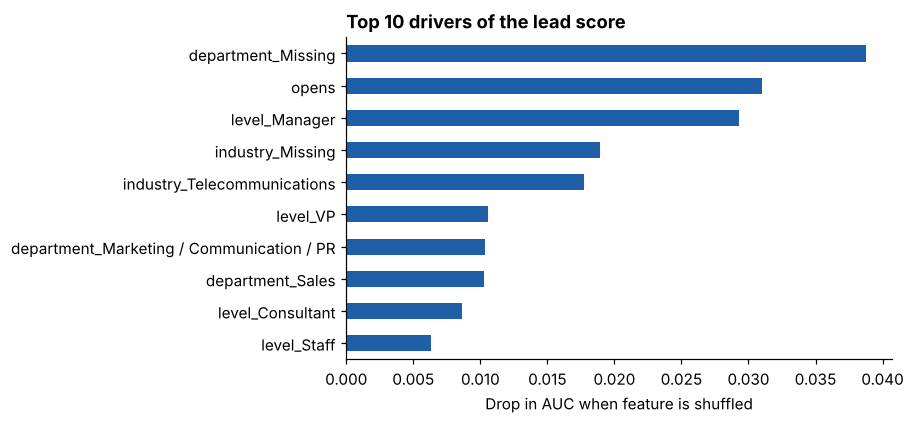

In [11]:
best_cols = BEHAVIOR if best_key[0] == 'Role + contact behavior' else []
Xd = design(cust, ROLE, best_cols)
Xa, Xb, ya, yb2 = train_test_split(Xd, cust.converted, test_size=0.2, stratify=cust.converted, random_state=SEED)
best_model = models()[best_key[1]].fit(Xa, ya)
pi = permutation_importance(best_model, Xb, yb2, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xb.columns).sort_values(ascending=False).head(10)
display(imp.round(4).rename('AUC drop when shuffled'))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
imp[::-1].plot.barh(ax=ax, color='#1f5fa8')
ax.set_xlabel('Drop in AUC when feature is shuffled'); ax.set_title('Top 10 drivers of the lead score', loc='left', fontweight='bold')
fig.savefig('charts/feature_importance.png', dpi=160, bbox_inches='tight')

## 8. Segment charts (existing-customer contacts)

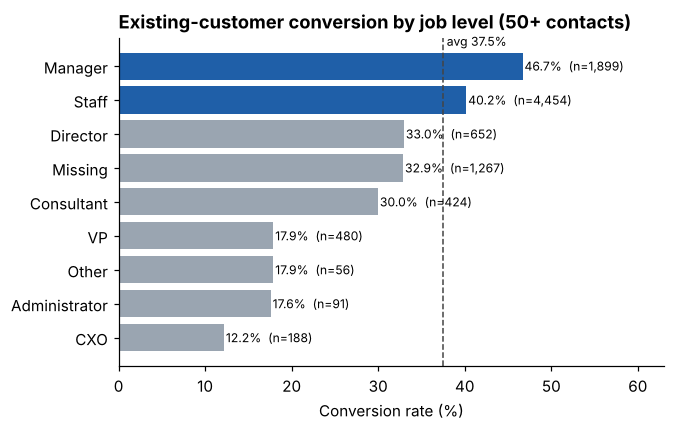

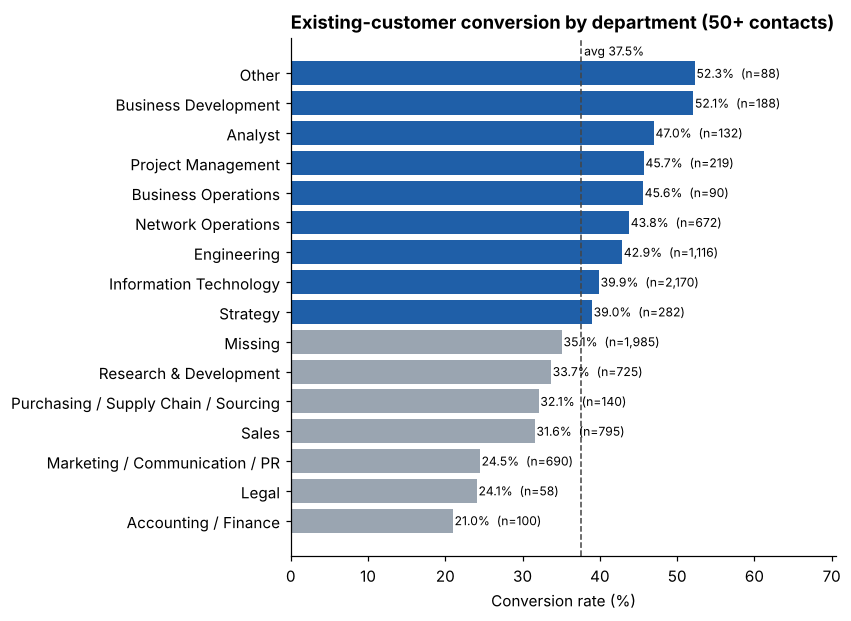

In [12]:
overall = cust.converted.mean() * 100
for name, t, fname in [('job level', cust_level, 'conversion_by_level'), ('department', cust_dept, 'conversion_by_department')]:
    t2 = t.sort_values('rate_%')
    fig, ax = plt.subplots(figsize=(6.4, 0.32 * len(t2) + 1))
    ax.barh(t2.index.astype(str), t2['rate_%'], color=['#1f5fa8' if v > overall else '#9aa5b1' for v in t2['rate_%']])
    ax.axvline(overall, color='#444', ls='--', lw=1); ax.text(overall, len(t2) - 0.4, f' avg {overall:.1f}%', fontsize=8)
    for i, (v, n) in enumerate(zip(t2['rate_%'], t2['leads'])):
        ax.text(v + 0.2, i, f'{v:.1f}%  (n={n:,})', va='center', fontsize=8)
    ax.set_xlabel('Conversion rate (%)'); ax.set_title(f'Existing-customer conversion by {name} (50+ contacts)', loc='left', fontweight='bold')
    ax.set_xlim(0, t2['rate_%'].max() * 1.35)
    fig.savefig(f'charts/{fname}.png', dpi=160, bbox_inches='tight')

## 9. SQL version of the lead-level table
`lead_level.sql` builds the same one-row-per-lead table from an `activities` table. Checked here in SQLite against the pandas result.

In [13]:
sql = open('lead_level.sql').read()
con = sqlite3.connect(':memory:')
raw[['leadId', 'industry', 'department__c', 'level__c', 'leadstatus', 'activityDate']].assign(
    activityDate=raw.activityDate.astype(str)).to_sql('activities', con, index=False)
stmts = [s.strip() for s in sql.split(';') if s.strip()]
for s in stmts[:-1]:
    con.execute(s)
sql_level = pd.read_sql(stmts[-1], con)
display(sql_level)
sql_leads = pd.read_sql('SELECT leadId, converted, level FROM leads', con).merge(
    leads[['leadId', 'converted', 'level']], on='leadId', suffixes=('_sql', '_pd'))
print(f"SQL leads: {len(sql_leads):,} | converted flag matches pandas: {(sql_leads.converted_sql == sql_leads.converted_pd).mean():.1%} of leads"
      f" | level matches: {(sql_leads.level_sql == sql_leads.level_pd).mean():.1%} (SQL uses each lead's most common level; pandas the first listed)")

SQL leads: 34,296 | converted flag matches pandas: 100.0% of leads | level matches: 99.8% (SQL uses each lead's most common level; pandas the first listed)


,level,leads,conversions,conversion_rate_pct
0,Staff,15576,1865,12.0
1,Manager,7922,904,11.4
2,Consultant,1124,127,11.3
3,Director,2301,230,10.0
4,Missing,4710,426,9.0
5,VP,1113,88,7.9
6,Dept. Heads,113,7,6.2
7,CXO,472,24,5.1
8,Administrator,360,17,4.7
9,Other,549,14,2.6


## 10. Files for a Tableau Public dashboard

In [14]:
out = cust[['level', 'department', 'industry', 'first_seen', 'converted']].copy()
out['score'] = s_best.round(4)
out['decile'] = pd.qcut(out.score.rank(method='first', ascending=False), 10, labels=range(1, 11)).astype(int)
out.to_csv('tableau/lead_scores.csv', index=False)
segs = pd.concat([t.assign(segment_type=st, population=pop).rename_axis('segment').reset_index()
                  for t, st, pop in [(by_level, 'level', 'all leads'), (by_dept, 'department', 'all leads'),
                                     (cust_level, 'level', 'existing customers'), (cust_dept, 'department', 'existing customers')]])
segs.to_csv('tableau/segments.csv', index=False)
print('wrote tableau/lead_scores.csv', out.shape, 'and tableau/segments.csv', segs.shape)

wrote tableau/lead_scores.csv (9543, 7) and tableau/segments.csv (55, 6)


## 11. Summary of numbers

In [15]:
b = results.set_index(['features', 'model'])
summary = {
    'leads (all)': f"{len(leads):,}", 'conversion rate (all)': f"{leads.converted.mean():.1%}",
    'share of conversions from existing customers': f"{cust_share:.1%}",
    'conversion: existing customers vs others': f"{cust.converted.mean():.1%} vs {data[~data.is_customer].converted.mean():.1%}",
    'customers: Manager / Staff vs CXO': f"{cust_level.loc['Manager','rate_%']}% / {cust_level.loc['Staff','rate_%']}% vs {cust_level.loc['CXO','rate_%']}%",
    'baseline AUC, all leads (random split, role only, RF)': f"{roc_auc_score(yte, p):.3f}",
    'customer model AUC, role only (5-fold CV)': f"{b.loc[('Role only', best_key[1]), 'AUC']:.3f}",
    'customer model AUC, best (5-fold CV)': f"{b.loc[best_key, 'AUC']:.3f}  [{best_key[0]}, {best_key[1]}]",
    'top 10% conversion rate / lift (best)': f"{b.loc[best_key, 'top 10% conv %']}% / {b.loc[best_key, 'lift']:.2f}x",
    'call top 30% -> conversions captured (best)': f"{cap_at(yb, s_best, .3):.0%}",
}
display(pd.Series(summary, name='value'))

,value
leads (all),"34,296"
conversion rate (all),10.8%
share of conversions from existing customers,96.7%
conversion: existing customers vs others,37.5% vs 0.5%
customers: Manager / Staff vs CXO,46.7% / 40.2% vs 12.2%
"baseline AUC, all leads (random split, role only, RF)",0.690
"customer model AUC, role only (5-fold CV)",0.674
"customer model AUC, best (5-fold CV)","0.691 [Role + contact behavior, Random Forest]"
top 10% conversion rate / lift (best),64.6% / 1.72x
call top 30% -> conversions captured (best),43%
